# CSCI1409 Deep Learning · Week 9 Homework (starter)
## Repair a parcel-label reader

**Individual · about 2.5–3 hours · CPU only.** The full task description is in the handout *CSCI1409_Week09_OCR_Homework*. In this notebook you **write code and run it**: there is no hand calculation anywhere.

**Marks (internal guide):** Part 0 reading 15 · Part 1 CTC decoder 15 · Part 2 trustworthy scoring 25 · Part 3 two fixes 30 · Part 4 evidence 15.

**Rules**
1. Do the **reading first** (Part 0). Answer in your own words and name the source.
2. Cells marked **PROVIDED** are given: do not edit them. Cells marked **TODO** are yours.
3. Use validation images to make choices. **Do not run OCR on test images until your recipe is frozen** (Part 3).
5. Before you submit: **Kernel → Restart & Run All**, so every number comes from this run.

## Setup (PROVIDED)
You need the **Tesseract** program (a separate engine; `pip` alone is not enough) with English data.
- **Google Colab:** run `!apt-get install -y tesseract-ocr` and `!pip install rapidfuzz` once, then restart the runtime.
- **Your own computer:** install Tesseract (see the setup link in the handout) and `pip install rapidfuzz pandas matplotlib pillow`.
- Unpack the student pack (the folder with `manifest.csv` and the images) next to this notebook.

In [4]:
# PROVIDED: setup and helpers. Do not edit.
import os, io, glob, json, shutil, subprocess, datetime
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter
from rapidfuzz.distance import Levenshtein

assert shutil.which("tesseract"), "Tesseract is not installed: see the setup note above."
print(subprocess.run(["tesseract", "--version"], capture_output=True, text=True).stdout.splitlines()[0])
assert "eng" in subprocess.run(["tesseract", "--list-langs"], capture_output=True, text=True).stdout, "English language data missing."

hits = glob.glob("**/manifest.csv", recursive=True)
assert hits, "manifest.csv not found: unpack the student pack next to this notebook."
PACK_DIR = os.path.dirname(hits[0])
manifest = pd.read_csv(hits[0])
REF_COL = next(c for c in ("reference", "target", "text", "label") if c in manifest.columns)   # column with the true string
CONDITIONS = ["clean", "blur", "rotation", "shadow"]
val_rows  = manifest[manifest["split"].astype(str).str.startswith("val")]
test_rows = manifest[manifest["split"].astype(str).str.startswith("test")]
_files = {os.path.basename(p): p for p in glob.glob(os.path.join(PACK_DIR, "**", "*.*"), recursive=True)}

def load_image(filename):
    """Every image is loaded as grayscale. This is part of loading, not of your recipes."""
    return Image.open(_files[filename]).convert("L")

def ocr(img):
    """Fixed OCR call: Tesseract, English, LSTM engine, one text line (--oem 1 --psm 7). Do not change."""
    buf = io.BytesIO(); img.save(buf, format="PNG")
    r = subprocess.run(["tesseract", "stdin", "stdout", "-l", "eng", "--oem", "1", "--psm", "7"],
                       input=buf.getvalue(), capture_output=True)
    return r.stdout.decode("utf-8", errors="replace").strip()

def show(images, titles, width=3.2):
    fig, axes = plt.subplots(1, len(images), figsize=(width * len(images), 1.6), squeeze=False)
    for ax, im, t in zip(axes[0], images, titles):
        ax.imshow(im, cmap="gray"); ax.set_title(t, fontsize=8); ax.axis("off")
    plt.show()

def report_table(df):
    """Table per condition and overall: images, reference characters, edits, corpus CER, exact match. Uses YOUR score()."""
    rows = []
    for name, part in [(c, df[df["condition"] == c]) for c in CONDITIONS] + [("ALL", df)]:
        if len(part) == 0: continue
        s = score(list(part["norm_reference"]), list(part["norm_prediction"]))
        rows.append({"condition": name, "images": s["images"], "ref_chars": s["chars"], "edits": s["edits"],
                     "corpus_CER": round(s["cer"], 3), "exact_match": f'{s["exact_n"]}/{s["images"]} ({100*s["exact_n"]/s["images"]:.0f}%)'})
    return pd.DataFrame(rows).set_index("condition")

def freeze(config):
    """Writes chosen_config.json with a timestamp. Run it once, BEFORE any test OCR."""
    config = dict(config); config["frozen_at"] = datetime.datetime.now().isoformat(timespec="seconds")
    with open("chosen_config.json", "w") as f: json.dump(config, f, indent=2)
    print("Frozen at", config["frozen_at"])

def require_frozen():
    assert os.path.exists("chosen_config.json"), "Freeze your recipe (Part 3.4) BEFORE touching the test set."

PRED_COLUMNS = ["filename", "base_id", "split", "condition", "system", "reference", "raw_prediction",
                "norm_reference", "norm_prediction", "edits", "ref_length", "exact_match"]

def show_example(filename, base_df, fix_df):
    """Shows one test crop with the reference and both predictions."""
    b = base_df[base_df["filename"] == filename].iloc[0]; f = fix_df[fix_df["filename"] == filename].iloc[0]
    show([load_image(filename)], [f'{filename} | ref {b["norm_reference"]} | baseline "{b["norm_prediction"]}" ({b["edits"]} edits) | '
                                  f'fix "{f["norm_prediction"]}" ({f["edits"]} edits)'], width=9)

print("Pack:", PACK_DIR, "| images:", len(manifest), "| validation:", len(val_rows), "| test:", len(test_rows), "| reference column:", REF_COL)
manifest.head(3)

AssertionError: Tesseract is not installed: see the setup note above.

# Part 0 · Reading check (15 marks, about 40 minutes of reading)
Read **before** coding: the lecture slides; Hannun (2017) *Sequence Modeling with CTC* (distill.pub/2017/ctc: Introduction and the *Alignment* part); the Tesseract page *Improving the quality of the output* (the *Image processing* section); Shi, Bai, Yao (2015) *CRNN* (arxiv.org/abs/1507.05717: abstract, introduction, architecture figure).
Answer in 1–3 sentences each, in your own words, and end with the source, e.g. *(Hannun, Alignment)*. No source or copied wording: at most 1 of 3 marks.

**R1.** Why can one image classifier not read a whole label such as `COFFEE-55`? What changes between reading `7`, `BOOK` and `COFFEE-55`?

**Your answer:** A classifier picks one class from a fixed list, so it can read one symbol like `7`, but a label is a sequence of unknown length and the number of possible strings is effectively unlimited. Going from `7` to `BOOK` to `COFFEE-55` the output length grows and letters repeat, so we need a model that outputs a sequence and an alignment between image positions and characters. (Lecture slides, “Five jobs inside an OCR system”; Hannun, Introduction)

**R2.** In a CRNN reader, what job does each part do: the CNN, the BiLSTM, and CTC? Why do we still need a text detector for a full photograph?

**Your answer:** The CNN turns the line image into a sequence of feature columns, the BiLSTM reads this sequence in both directions to give per-column character scores using context, and CTC turns these per-column scores into the final text without per-character position labels. CRNN only reads a cropped text line, so in a full photograph a detector must first find where the text is. (Shi, Bai, Yao, Abstract and Fig. 1; Lecture slides)

**R3.** CTC decoding has two steps. Which two, in which order? What is the blank for, and why does `BOOK` need one between the two O's?

**Your answer:** First merge adjacent identical symbols, then remove the blanks. The blank marks a position with no character and separates real repeats; without a blank between the two O's they would be merged into one and BOOK would become BOK. (Hannun, Alignment)

**R4.** Name two image problems that the Tesseract documentation says can hurt recognition, and one fix for each.

**Your answer:** Skewed (rotated) text lowers accuracy, fix: deskew (rotate the page back). Uneven lighting or dark/noisy background makes binarisation fail, fix: better binarisation (e.g. adaptive thresholding) or noise removal; text that is too small can be fixed by rescaling. (Tesseract docs, Image processing)

**R5.** Why report exact match as well as CER for a product code?

**Your answer:** CER counts small character errors, so a code with one wrong digit gets a low CER, but for a product code one wrong character means the wrong product. Exact match shows how many codes are fully usable. (Lecture slides, “Count the edits”)

# Part 1 · Build the CTC decoder (15 marks)
CTC turns a path of per-position symbols into text: **(1) merge adjacent identical symbols, (2) remove blanks.** `∅` is the blank symbol, not a space.

In [ ]:
def ctc_collapse(path, blank="∅"):
    merged = [t for i, t in enumerate(path) if i == 0 or t != path[i - 1]]
    return "".join(t for t in merged if t != blank)

In [ ]:
# PROVIDED: checks. Passing is necessary; you must also be able to explain your code.
assert ctc_collapse([]) == ""                                   # empty path
assert ctc_collapse(["∅", "∅", "∅"]) == ""                      # only blanks
assert ctc_collapse(list("LLLL")) == "L"                        # adjacent repeats merge
assert ctc_collapse(["L", "L", "∅", "L", "L"]) == "LL"          # a blank keeps two identical letters
for p in (["B","B","∅","O","O","∅","O","K","K"], ["C","C","∅","A","A","T","T"], ["L","L","∅","L","L"], ["L","L","L","L"]):
    print("".join(p), "->", repr(ctc_collapse(p)))
print("All CTC checks passed")

BB∅OO∅OKK -> 'BOOK'
CC∅AATT -> 'CAT'
LL∅LL -> 'LL'
LLLL -> 'L'
All CTC checks passed


In [ ]:
def wrong_collapse(path, blank="∅"):
    no_blank = [t for t in path if t != blank]
    return "".join(t for i, t in enumerate(no_blank) if i == 0 or t != no_blank[i - 1])

BOOK_PATH = ["B", "B", "∅", "O", "O", "∅", "O", "K", "K"]
print(pd.DataFrame({"path": ["".join(BOOK_PATH)], "ctc_collapse": [ctc_collapse(BOOK_PATH)], "wrong_collapse": [wrong_collapse(BOOK_PATH)]}))

        path ctc_collapse wrong_collapse
0  BB∅OO∅OKK         BOOK            BOK


In [ ]:
PATH_1 = ["B", "O", "∅", "O", "K"]
PATH_2 = ["∅", "B", "B", "O", "O", "O", "∅", "∅", "O", "K", "∅"]
for p in (PATH_1, PATH_2):
    print("".join(p), "->", ctc_collapse(p))
assert PATH_1 != PATH_2 and ctc_collapse(PATH_1) == "BOOK" and ctc_collapse(PATH_2) == "BOOK", "Fix your two paths"
print("OK")

BO∅OK -> BOOK
∅BBOOO∅∅OK∅ -> BOOK
OK


**Part 1 answer** (2–3 sentences): look at your `wrong_collapse` output. What goes wrong, and why does the blank have to be removed *after* merging?

**Your answer:** `wrong_collapse` gives `BOK` instead of `BOOK`. Removing blanks first makes the two O's adjacent, so the merge step joins them into one. The blank is what separates a real double letter, so it must be removed only after merging.

# Part 2 · Build a baseline you can trust (25 marks)
Your scoring code must compare predictions with the reference text the same way every time and must not hide failures. Work with **validation images only** until Part 3.4.

### 2.1 Check the data (4 marks)

In [ ]:
assert len(manifest) == 48, "manifest must have 48 rows"
assert len(val_rows) == 24 and len(test_rows) == 24, "need 24 validation and 24 test rows"
assert (manifest.groupby("base_id")["split"].nunique() == 1).all(), "a base_id appears in more than one split"
assert all(os.path.basename(f) in _files for f in manifest["filename"]), "an image file is missing"
for name, part in [("validation", val_rows), ("test", test_rows)]:
    counts = part["condition"].value_counts()
    assert set(counts.index) == set(CONDITIONS) and (counts == 6).all(), f"{name}: need 6 images per condition"
_files.update({f: _files[os.path.basename(f)] for f in manifest["filename"]})
print("Data checks passed")

Data checks passed


### 2.2 Normalize text (4 marks)
Convert to uppercase and remove **all** whitespace. Keep punctuation, hyphens and digits. Do **not** change `O` into `0` or `I` into `1`. Apply it to references **and** predictions.

In [ ]:
def normalize(text):
    return "".join(str(text).upper().split())

In [ ]:
# PROVIDED check
assert normalize(" wb-48 17\n") == "WB-4817" and normalize("b0ok") == "B0OK" and normalize("") == ""
print("normalize OK")

normalize OK


### 2.3 Corpus CER and exact match (8 marks)
`corpus_CER = total edits / total reference characters` and `exact match = identical normalized pairs / images`. Use `Levenshtein.distance(a, b)` for the edit count of one pair. Pass **already normalized** strings.

In [ ]:
def score(refs, preds):
    assert len(refs) == len(preds), "refs and preds must have equal length"
    edits = sum(Levenshtein.distance(r, p) for r, p in zip(refs, preds))
    chars = sum(len(r) for r in refs)
    exact_n = sum(r == p for r, p in zip(refs, preds))
    return {"images": len(refs), "chars": chars, "edits": edits, "cer": edits / chars if chars else 0.0, "exact_n": exact_n}

In [ ]:
# PROVIDED check on three toy pairs (BOOK->BOK, CAT->CATS, R7->R7)
s = score(["BOOK", "CAT", "R7"], ["BOK", "CATS", "R7"])
assert (s["images"], s["chars"], s["edits"], s["exact_n"]) == (3, 9, 2, 1) and abs(s["cer"] - 2/9) < 1e-9, s
print("score OK:", s)

score OK: {'images': 3, 'chars': 9, 'edits': 2, 'cer': 0.2222222222222222, 'exact_n': 1}


In [ ]:
refs, preds = ["BOOK", "CAT", "R7"], ["BOK", "CATS", "R7"]
per_image = [Levenshtein.distance(r, p) / len(r) for r, p in zip(refs, preds)]
print(f"corpus CER = {s['cer']:.4f} | mean per-image CER = {sum(per_image) / len(per_image):.4f}")

corpus CER = 0.2222 | mean per-image CER = 0.1944


**2.3 answer** (2 sentences): why is the corpus CER not the average of per-image CERs, and why must an empty prediction stay in the table?

**Your answer:** Corpus CER divides all edits by all reference characters, so every character has equal weight, while the per-image average gives a short label the same weight as a long one (here 0.222 vs 0.194). An empty prediction is a real failure (edits = reference length); removing it would hide errors and make the CER look better than it is.

### 2.4 Run the baseline on validation (9 marks)
One function runs any system (a preprocessing function, or none) on a set of rows. Every image must give one row, **including empty OCR outputs**.

In [ ]:
def run_system(rows, preprocess=None, system="baseline"):
    out = []
    for _, r in rows.iterrows():
        img = load_image(r["filename"])
        if preprocess is not None:
            img = preprocess(img)
        raw = ocr(img)
        nref, npred = normalize(r[REF_COL]), normalize(raw)
        out.append({"filename": r["filename"], "base_id": r["base_id"], "split": r["split"], "condition": r["condition"],
                    "system": system, "reference": r[REF_COL], "raw_prediction": raw,
                    "norm_reference": nref, "norm_prediction": npred, "edits": Levenshtein.distance(nref, npred),
                    "ref_length": len(nref), "exact_match": nref == npred})
    return pd.DataFrame(out, columns=PRED_COLUMNS)

In [ ]:
val_base = run_system(val_rows)
display(report_table(val_base))
display(val_base.sort_values("edits", ascending=False).head(5))

,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,47,0,0.000,6/6 (100%)
blur,6,47,0,0.000,6/6 (100%)
rotation,6,47,41,0.872,0/6 (0%)
shadow,6,47,44,0.936,0/6 (0%)
ALL,24,188,85,0.452,12/24 (50%)


,filename,base_id,split,condition,system,reference,raw_prediction,norm_reference,norm_prediction,edits,ref_length,exact_match
6,images/V02_rotation.png,V02,validation,rotation,baseline,BOOK-220,,BOOK-220,,8,8,False
18,images/V05_rotation.png,V05,validation,rotation,baseline,BOX-6072,,BOX-6072,,8,8,False
22,images/V06_rotation.png,V06,validation,rotation,baseline,ROOM-406,,ROOM-406,,8,8,False
23,images/V06_shadow.png,V06,validation,shadow,baseline,ROOM-406,Biss,ROOM-406,BISS,8,8,False
19,images/V05_shadow.png,V05,validation,shadow,baseline,BOX-6072,a,BOX-6072,A,8,8,False


**2.4 answer** (2–3 sentences): which condition is hardest for the baseline, and what do you actually see in the failing rows (empty? partly right? wrong letters?)

**Your answer:** Clean and blur are read perfectly (CER 0.000), the failures are only in rotation (0.872) and shadow (0.936), so shadow is hardest. Four rotation images give completely empty output and the other two are partly right with wrong letters (`qpTy-2°`, `min-v1®`); shadow outputs are 1–4 garbage characters (`a`, `~~`, `Biss`), only a fragment of the end like `20` survives.

# Part 3 · Compare two fixes fairly (30 marks)
You may change the **image**, never the OCR call or the scoring. A recipe may look at pixels only: not at the filename, base_id, split, condition or reference text.

### 3.1 Predict first (4 marks)
Before running any fix: which condition will be hardest, and which operation might help it? Give a reason from what you see in the images.

**Your prediction:** Shadow will be hardest: the text is light gray on a darker gray gradient, so the contrast is very low and changes across the image. Flattening the background (estimate it with a large max filter and subtract it) and then autocontrast should help. Rotation will probably stay bad, because none of the simple operations can deskew without knowing the angle.

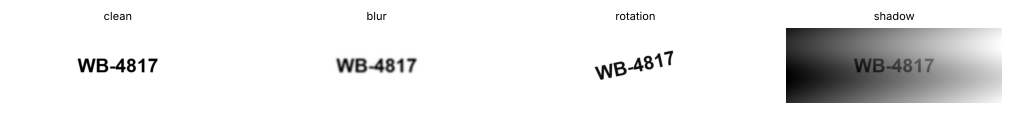

In [ ]:
# PROVIDED: look at one validation crop per condition (no OCR needed)
sample = [val_rows[val_rows["condition"] == c].iloc[0]["filename"] for c in CONDITIONS]
show([load_image(f) for f in sample], CONDITIONS)

### 3.2 Write exactly two recipes (8 marks)
Each recipe is a function `img -> img` using **at most three** Pillow operations. Ideas: `img.resize((w*2, h*2), Image.LANCZOS)`, `ImageOps.autocontrast(img)`, `img.filter(ImageFilter.SHARPEN)`, `img.filter(ImageFilter.MedianFilter(3))`, `img.point(lambda v: 255 if v > T else 0)` (threshold), `ImageOps.expand(img, border=20, fill=255)` (white border). Docs: pillow.readthedocs.io (ImageOps, ImageFilter).

In [ ]:
from PIL import ImageChops

def fix_a(img):
    img = ImageOps.autocontrast(img, cutoff=2)
    img = img.resize((img.width * 2, img.height * 2), Image.LANCZOS)
    return img.filter(ImageFilter.SHARPEN)

def fix_b(img):
    background = img.filter(ImageFilter.MaxFilter(21))
    img = ImageChops.subtract(img, background, scale=1.0, offset=255)
    return ImageOps.autocontrast(img, cutoff=1)

trials = []

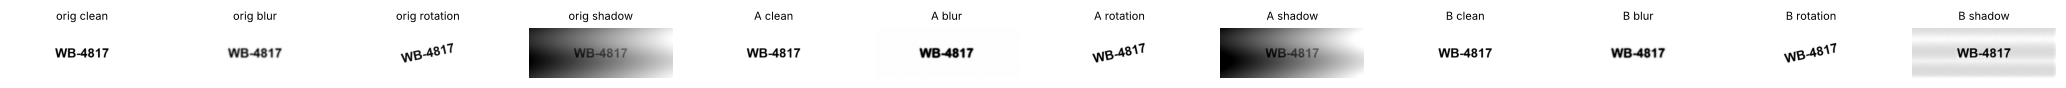

In [ ]:
# PROVIDED: see what your recipes do to one crop per condition
show([load_image(f) for f in sample] + [fix_a(load_image(f)) for f in sample] + [fix_b(load_image(f)) for f in sample],
     [f"orig {c}" for c in CONDITIONS] + [f"A {c}" for c in CONDITIONS] + [f"B {c}" for c in CONDITIONS], width=2.2)

### 3.3 Compare on validation (6 marks)

In [ ]:
val_a = run_system(val_rows, fix_a, "fix_a")
val_b = run_system(val_rows, fix_b, "fix_b")
trials.append(("fix_a: autocontrast(cutoff=2) -> resize x2 LANCZOS -> SHARPEN", round(score(list(val_a["norm_reference"]), list(val_a["norm_prediction"]))["cer"], 3)))
trials.append(("fix_b: MaxFilter(21) background -> subtract(offset=255) -> autocontrast(cutoff=1)", round(score(list(val_b["norm_reference"]), list(val_b["norm_prediction"]))["cer"], 3)))
for name, df in [("baseline", val_base), ("fix_a", val_a), ("fix_b", val_b)]:
    print(name); display(report_table(df))
print(pd.DataFrame(trials, columns=["trial", "validation corpus CER"]))

baseline


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,47,0,0.000,6/6 (100%)
blur,6,47,0,0.000,6/6 (100%)
rotation,6,47,41,0.872,0/6 (0%)
shadow,6,47,44,0.936,0/6 (0%)
ALL,24,188,85,0.452,12/24 (50%)


fix_a


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,47,0,0.000,6/6 (100%)
blur,6,47,0,0.000,6/6 (100%)
rotation,6,47,37,0.787,0/6 (0%)
shadow,6,47,46,0.979,0/6 (0%)
ALL,24,188,83,0.441,12/24 (50%)


fix_b


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,47,0,0.000,6/6 (100%)
blur,6,47,0,0.000,6/6 (100%)
rotation,6,47,34,0.723,0/6 (0%)
shadow,6,47,0,0.000,6/6 (100%)
ALL,24,188,34,0.181,18/24 (75%)


                                               trial  validation corpus CER
0  fix_a: autocontrast(cutoff=2) -> resize x2 LAN...                  0.441
1  fix_b: MaxFilter(21) background -> subtract(of...                  0.181


### 3.4 Choose and freeze (6 marks)
Choose by **lowest validation corpus CER** (tie: higher exact match). Then run `freeze(...)`: it writes `chosen_config.json` with a timestamp.

In [ ]:
CHOSEN = "fix_b"
config = {"chosen": CHOSEN,
          "operations": "1) ImageFilter.MaxFilter(21) -> background; 2) ImageChops.subtract(img, background, scale=1.0, offset=255); 3) ImageOps.autocontrast(cutoff=1)",
          "ocr": "tesseract --oem 1 --psm 7, lang eng",
          "normalization": "uppercase, remove whitespace",
          "reason": "fix_b has the lowest validation corpus CER: 0.181 (34/188 edits, 18/24 exact) vs fix_a 0.441 and baseline 0.452."}
freeze(config)

Frozen at 2026-11-06T20:55:56


### 3.5 Test, run once (6 marks)

In [ ]:
require_frozen()
test_base = run_system(test_rows)
test_final = run_system(test_rows, fix_b if CHOSEN == "fix_b" else fix_a, CHOSEN)
print("baseline"); display(report_table(test_base))
print(CHOSEN); display(report_table(test_final))

baseline


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,49,0,0.000,6/6 (100%)
blur,6,49,0,0.000,6/6 (100%)
rotation,6,49,21,0.429,1/6 (17%)
shadow,6,49,43,0.878,0/6 (0%)
ALL,24,196,64,0.327,13/24 (54%)


fix_b


,images,ref_chars,edits,corpus_CER,exact_match
condition,,,,,
clean,6,49,0,0.000,6/6 (100%)
blur,6,49,0,0.000,6/6 (100%)
rotation,6,49,22,0.449,0/6 (0%)
shadow,6,49,0,0.000,6/6 (100%)
ALL,24,196,22,0.112,18/24 (75%)


In [ ]:
# PROVIDED: saves all 120 required rows (validation: baseline + fix_a + fix_b = 72; test: baseline + chosen = 48)
all_preds = pd.concat([val_base, val_a, val_b, test_base, test_final], ignore_index=True)
assert len(all_preds) == 120 and list(all_preds.columns) == PRED_COLUMNS, "Expected 120 rows with the required columns"
all_preds.to_csv("predictions.csv", index=False)
print("Saved predictions.csv:", len(all_preds), "rows;", int((all_preds["norm_prediction"] == "").sum()), "empty predictions kept")

Saved predictions.csv: 120 rows; 12 empty predictions kept


# Part 4 · Explain the evidence (15 marks)

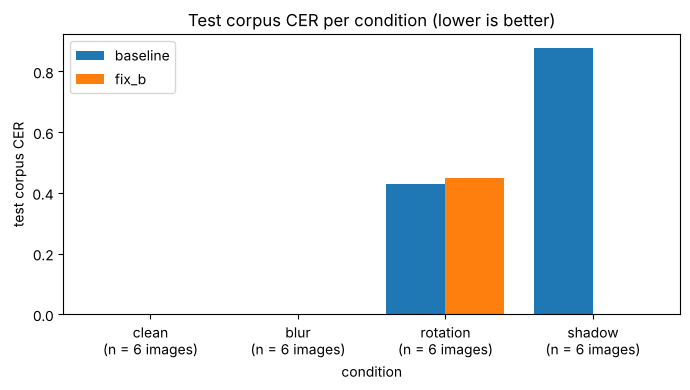

In [ ]:
tb, tf = report_table(test_base), report_table(test_final)
x = range(len(CONDITIONS))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([i - 0.2 for i in x], tb.loc[CONDITIONS, "corpus_CER"], 0.4, label="baseline")
ax.bar([i + 0.2 for i in x], tf.loc[CONDITIONS, "corpus_CER"], 0.4, label=CHOSEN)
ax.set_xticks(list(x)); ax.set_xticklabels([f"{c}\n(n = 6 images)" for c in CONDITIONS])
ax.set_xlabel("condition"); ax.set_ylabel("test corpus CER")
ax.set_title("Test corpus CER per condition (lower is better)")
ax.legend(); plt.tight_layout(); plt.show()

               filename condition  edits_base  edits_fix  delta
   images/T01_clean.png     clean           0          0      0
    images/T01_blur.png      blur           0          0      0
images/T01_rotation.png  rotation           7          7      0
  images/T01_shadow.png    shadow           7          0     -7
   images/T02_clean.png     clean           0          0      0
    images/T02_blur.png      blur           0          0      0
images/T02_rotation.png  rotation           5          6      1
  images/T02_shadow.png    shadow           9          0     -9
   images/T03_clean.png     clean           0          0      0
    images/T03_blur.png      blur           0          0      0
images/T03_rotation.png  rotation           3          2     -1
  images/T03_shadow.png    shadow           8          0     -8
   images/T04_clean.png     clean           0          0      0
    images/T04_blur.png      blur           0          0      0
images/T04_rotation.png  rotation       

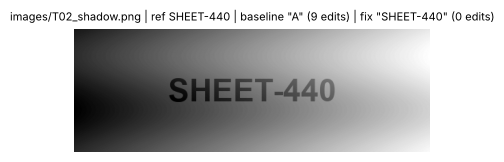

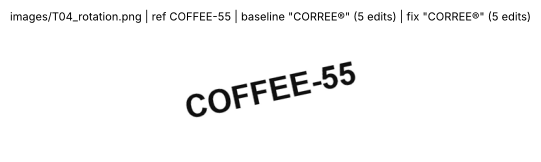

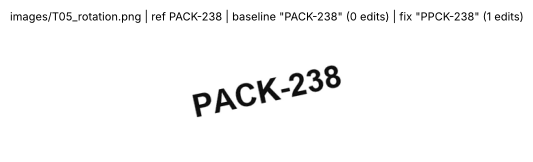

In [ ]:
cmp = test_base[["filename", "condition", "edits"]].merge(test_final[["filename", "edits"]], on="filename", suffixes=("_base", "_fix"))
cmp["delta"] = cmp["edits_fix"] - cmp["edits_base"]
print(cmp.to_string(index=False))
show_example("images/T02_shadow.png", test_base, test_final)
show_example("images/T04_rotation.png", test_base, test_final)
show_example("images/T05_rotation.png", test_base, test_final)

**Examples** (2–3 sentences each: first say what you *see* in the image, then, separately, what you *guess* happened):

1. **Improvement, `T02_shadow`.** See: light gray SHEET-440 on a gray gradient, baseline output `A` (9 edits), fix_b output `SHEET-440` (0 edits). Guess: Tesseract's binarisation lost the low-contrast text, and subtracting the estimated background made the letters dark on a flat white background.
2. **Unchanged, `T04_rotation`.** See: sharp black COFFEE-55 rotated about 12°, both systems output `CORREE®` (5 edits). Guess: fix_b does nothing to clean dark text on white, and the problem is the slant, which `--psm 7` (one straight line) cannot handle.
3. **Regression, `T05_rotation`.** See: rotated PACK-238, baseline `PACK-238` (0 edits), fix_b `PPCK-238` (1 edit). Guess: the max filter and autocontrast slightly changed the stroke edges, and on a rotated line this was enough to flip one uncertain letter A to P.

**Recommendation (80–150 words, 2 marks):** which recipe you would keep, which condition still needs work, and what these 48 synthetic images cannot tell you.

**Your answer:** I would keep fix_b (background subtraction with MaxFilter(21), then autocontrast). On test it cut corpus CER from 0.327 to 0.112 and raised exact match from 13/24 to 18/24, mainly because shadow went from 0.878 to 0.000, while clean and blur stayed perfect. Rotation still needs work: CER stayed about the same (0.429 vs 0.449) and fix_b even lost the only exact match, so a deskew step is needed. These 48 images are synthetic, with one font, one script, a fixed 12° angle and only 6 labels per split. They cannot tell how the reader works on real customer photos with other fonts, angles, glare, perspective or damaged labels, and the differences between systems rest on very few images.

**Two short answers (2 marks):** (a) Why can exact match matter more than a small CER for a product code? (b) Why can this crop-based test not tell you whether a detector misses labels in full photographs?

**Your answers:** (a) A product code is used as an exact key: one wrong character gives a different or non-existent product, so a small CER can still mean the label is useless; exact match counts the codes that work. (b) Every image is already a cropped single text line, so the detection step is skipped; a label that a detector misses in a full photo never reaches the reader and would not appear in this test at all.

# Sources and help
List every source (docs, articles, people) you used. Say clearly which parts you wrote yourself.

**Your note:** Week 9 lecture slides; Hannun (2017), distill.pub/2017/ctc; Tesseract docs “Improving the quality of the output”; Shi, Bai, Yao (2015), CRNN; Pillow ImageOps/ImageFilter/ImageChops docs; RapidFuzz Levenshtein docs. Answers and code prepared with help of an AI assistant (Claude).

**Submit on Teams before the next lecture begins:** this executed notebook, `predictions.csv` (120 rows) and `chosen_config.json`. After the lecture starts, homework is not accepted.